# Notebook 03: Filtering, spectra and signal-to-noise

**Goal (about 1.5 hours):** apply the signal-processing steps that come before any splitting measurement, and see that each one is a choice with consequences.

This is the lesson closest to an ECE course. Read along with ObsPy's [Filtering Seismograms](https://docs.obspy.org/tutorial/code_snippets/filtering_seismograms.html) page and Seismo-Live's [07 Basic Processing Exercise](https://seismo-live.github.io/html/ObsPy/07_Basic_Processing_Exercise_wrapper.html).

In [1]:
# --- setup: make the repo importable and keep figures inline ---
import sys, warnings
from pathlib import Path
REPO = Path.cwd().parent if (Path.cwd() / "../rainier_sws").exists() else Path.cwd()
sys.path.insert(0, str(REPO))
warnings.filterwarnings("ignore")
%matplotlib inline
import numpy as np, pandas as pd, matplotlib.pyplot as plt
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})
from rainier_sws import paths, data, measure, quality, stats
print("repo:", REPO)

repo: /Users/mhemmett/Seismology/rainier-sws-tutorials


In [2]:
import obspy
cat = data.load_station_catalog("STAR")
row = cat[cat.evid == 61504668].iloc[0]
ev = data.get_event_stream("STAR", row, allow_download=False)
origin, p_time, s_time, p_off, s_off = measure.pick_offsets(ev, row)
fs = ev[0].stats.sampling_rate
print("sampling rate", fs, "Hz; P at", round(p_off, 2), "s, S at", round(s_off, 2), "s after trace start")

sampling rate 100.0 Hz; P at 5.88 s, S at 6.47 s after trace start


## 1. What is in the signal: the spectrum

Compute the amplitude spectrum of a short window around the S wave on one horizontal channel, and of a noise window before P. The ratio of the two is where the "signal" lives in frequency.

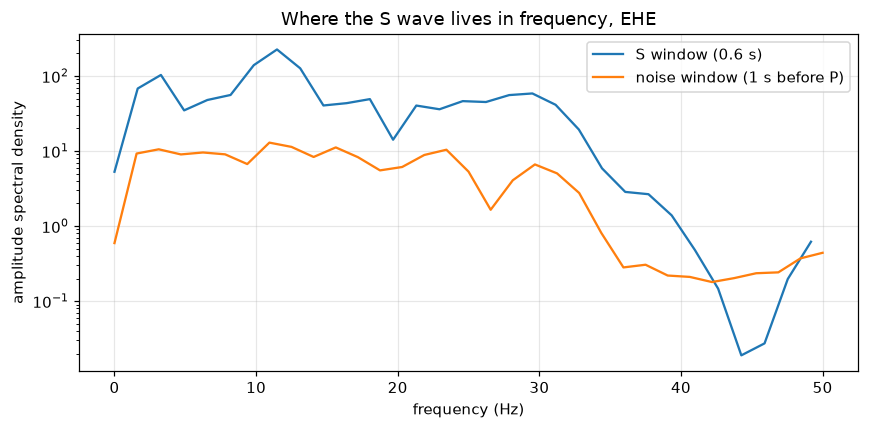

In [3]:
from scipy.signal import welch
tr = ev.select(channel="??E")[0].copy().detrend("linear")
def window(tr, t_start, t_end):
    return tr.slice(tr.stats.starttime + t_start, tr.stats.starttime + t_end).data.astype(float)
s_win = window(tr, s_off - 0.1, s_off + 0.5)
n_win = window(tr, p_off - 1.2, p_off - 0.2)
f_s, P_s = welch(s_win, fs=fs, nperseg=64); f_n, P_n = welch(n_win, fs=fs, nperseg=64)
fig, ax = plt.subplots(figsize=(8, 4))
ax.semilogy(f_s, np.sqrt(P_s), label="S window (0.6 s)"); ax.semilogy(f_n, np.sqrt(P_n), label="noise window (1 s before P)")
ax.set_xlabel("frequency (Hz)"); ax.set_ylabel("amplitude spectral density"); ax.legend()
ax.set_title("Where the S wave lives in frequency, EHE")
plt.tight_layout()

The S energy stands well above the noise from the lowest frequency resolved here (about 1.5 Hz) to about 35 Hz, strongest between about 3 and 13 Hz. Above about 40 Hz the signal has decayed into the noise. A bandpass filter keeps the part of the spectrum where the earthquake wins.

## 2. Bandpass filtering

ObsPy wraps scipy's Butterworth design. `corners` is the filter order; `zerophase=True` runs it forwards and backwards so arrival times are not shifted (important when the quantity you measure is a 0.02 s delay!). Note, though, that the pipeline's own filter bank (section 4) uses ObsPy's default, `zerophase=False`; exercise 1 measures what that does. Watch how the same S wave looks through three different bands.

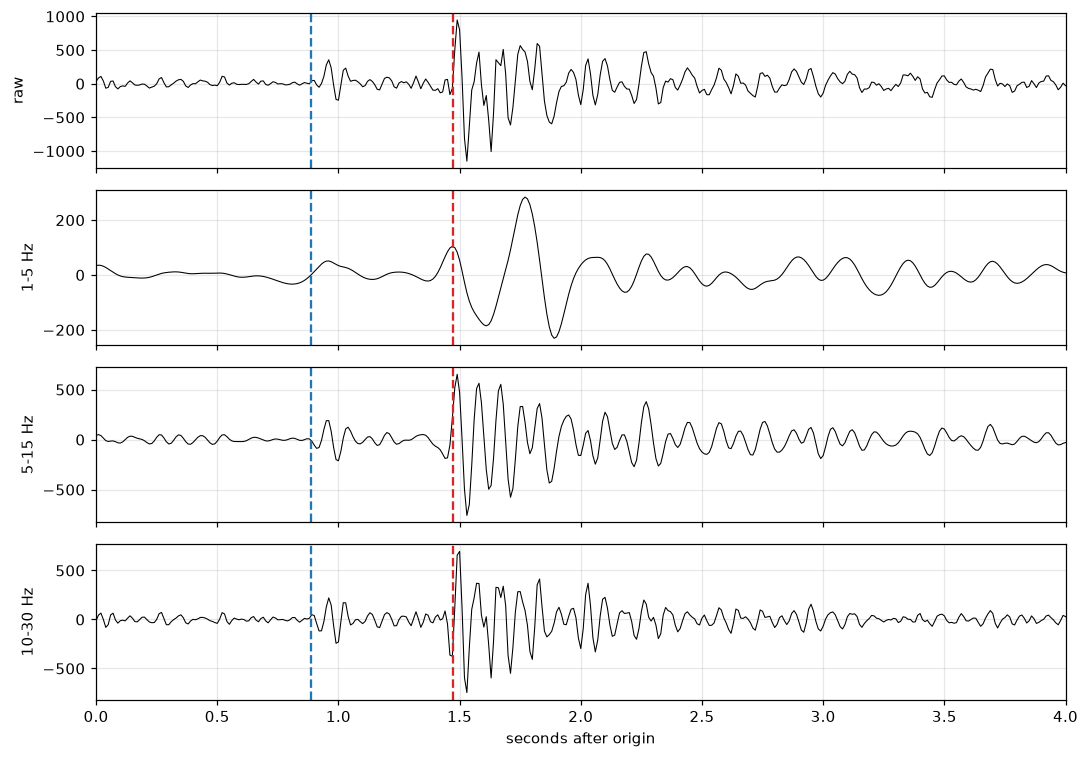

In [4]:
bands = [(1, 5), (5, 15), (10, 30)]
fig, axes = plt.subplots(len(bands) + 1, 1, figsize=(10, 7), sharex=True)
t = tr.times(reftime=origin)
axes[0].plot(t, tr.data, "k", lw=0.7); axes[0].set_ylabel("raw")
for ax, (lo, hi) in zip(axes[1:], bands):
    f = tr.copy().filter("bandpass", freqmin=lo, freqmax=hi, corners=2, zerophase=True)
    ax.plot(t, f.data, "k", lw=0.7); ax.set_ylabel(f"{lo}-{hi} Hz")
for ax in axes:
    ax.axvline(p_time - origin, color="tab:blue", ls="--"); ax.axvline(s_time - origin, color="tab:red", ls="--")
axes[-1].set_xlabel("seconds after origin"); axes[-1].set_xlim(0, 4)
plt.tight_layout()

## 3. Signal-to-noise ratio, defined precisely

"SNR" means nothing until you say which windows and which statistic. The research pipeline uses an MFAST/Baillard-style definition: mean absolute amplitude in a window after the S pick divided by mean absolute amplitude in a window before it, averaged over the two horizontal channels. Here is a simple version so you see the idea; the pipeline's exact version is `sws_functions._s_wave_snr_prefiltered`.

In [5]:
def simple_snr(tr, s_off, pre=0.4, post=0.2):
    sig = window(tr, s_off, s_off + post); noise = window(tr, s_off - pre, s_off)
    return np.mean(np.abs(sig)) / np.mean(np.abs(noise))
for lo, hi in bands:
    f = tr.copy().filter("bandpass", freqmin=lo, freqmax=hi, corners=2, zerophase=True)
    print(f"{lo:>3}-{hi:<3} Hz  SNR = {simple_snr(f, s_off):5.2f}")
print(f"raw        SNR = {simple_snr(tr, s_off):5.2f}")

  1-5   Hz  SNR =  5.97
  5-15  Hz  SNR =  8.08
 10-30  Hz  SNR =  5.92
raw        SNR =  7.92


## 4. The filter bank: letting the data choose the band

Rather than pick one band for all 900 events, the pipeline tries 14 candidate bands (from MFAST, Savage et al., 2010) and keeps the one with the highest S-wave SNR for each event. That is adaptive, but it is also a *choice* made by an SNR estimate that is itself noisy. Let's look at the SNR landscape across the bank for our event.

chosen band: (5.0, 10.0)  SNR: 14.0  dominant period (samples): 11.323076923076924


Text(0.5, 1.0, '14-band filter bank for evid 61504668 at STAR')

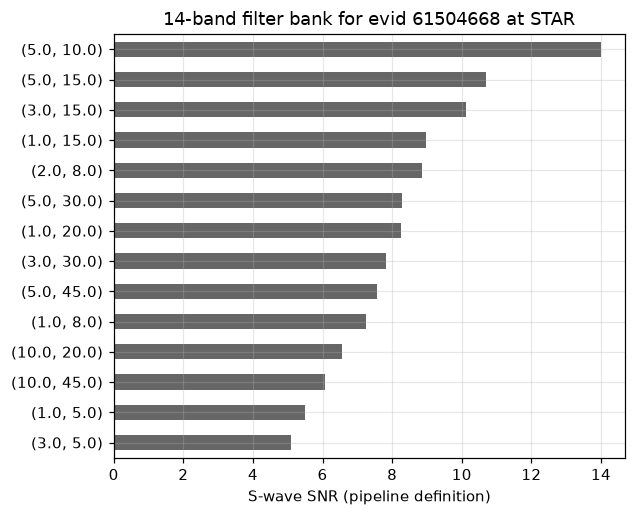

In [6]:
from rainier_sws import sws_functions as swsf
band, best_stream, snr, domp, snr_by_band = swsf.try_filters(ev.copy(), p_time, s_time)
tab = pd.Series(snr_by_band).sort_values(ascending=False)
print("chosen band:", band, " SNR:", round(snr, 2), " dominant period (samples):", domp)
ax = tab.plot.barh(figsize=(6, 5), color="0.4"); ax.set_xlabel("S-wave SNR (pipeline definition)"); ax.invert_yaxis()
ax.set_title("14-band filter bank for evid 61504668 at STAR")

Notice that several bands are close to the top. If the second-best band had been chosen, would the splitting answer change? That is exactly the kind of question notebook 07 asks, and the reason the band is recorded in every results row (`filter_band`).

## 5. Dominant period

Splitting delay times are compared with the wave's dominant period: a delay longer than half a period is almost certainly a cycle skip (the grid search matched the wrong wiggle). The pipeline estimates the dominant period from the filtered S window with a Welch spectrum (Baillard et al., 2014, as implemented in SWSPy), separately on N and E in a window from 0.1 s before S to 0.3 s after, and averages the two (`_s_wave_snr_prefiltered` in `sws_functions.py`). Done that way it reproduces the number the filter bank printed in section 4; on one channel or a different window it would not.

In [7]:
from swspy.splitting.split_windowcheck import get_dominant_period_baillard
periods = {}
for comp in "NE":
    seg = window(best_stream.select(channel=f"??{comp}")[0], s_off - 0.1, s_off + 0.3)
    periods[comp], _ = get_dominant_period_baillard(seg, fs)   # returns (period in samples, frequency in Hz)
T_samples = np.mean(list(periods.values()))
print("per channel (samples):", {k: round(v, 1) for k, v in periods.items()})
print(f"dominant period = {T_samples:.1f} samples = {T_samples / fs:.3f} s  ->  dominant frequency {fs / T_samples:.1f} Hz"
      f"  (filter bank in section 4: {domp:.1f} samples)")
print(f"half-period cycle-skip limit on dt = {T_samples / fs / 2:.3f} s")

per channel (samples): {'N': 12.8, 'E': 9.8}
dominant period = 11.3 samples = 0.113 s  ->  dominant frequency 8.8 Hz  (filter bank in section 4: 11.3 samples)
half-period cycle-skip limit on dt = 0.057 s


## 6. Exercises

1. Change `corners` to 4 and `zerophase` to False in section 2. Measure the shift of the S onset by eye. The pipeline's filter bank (`swsf.try_filters`) uses 2 corners and ObsPy's default `zerophase=False`: what does that do to the S wave relative to the pick, and does it matter for a splitting measurement?
2. Change the SNR window lengths (`pre`, `post`) in `simple_snr` to 0.2/0.1 and 1.0/0.5. How much does the SNR move? Would the event pass an "SNR at least 2" gate under each?
3. Run the filter bank on five more events from `cat`. How often is the chosen band 5-10 or 5-15 Hz? Is there one band that would be a sensible fixed choice?
4. (Stretch) Compute the spectrogram of the whole 20 s trace (`scipy.signal.spectrogram`). Where do P, S and coda sit in time and frequency?

Next: `04_what_is_shear_wave_splitting.ipynb`, where the physics finally shows up.

## 7. Example solutions

One way to do each exercise. Try them yourself first; the commentary is about the figure-3 event and the events sampled here.

### Exercise 1: a causal filter shifts the arrival

"By eye" is hard at 0.01 s per sample, so measure it as well. Cross-correlating the filtered wiggles is ambiguous (a shift of one whole period, about 0.1 s here, matches almost as well as no shift), so compare **envelopes** instead: the smooth outline of the wave from the Hilbert transform. Two measures: the lag that best aligns the causal envelope with the zero-phase one, and the time the envelope first reaches half its maximum. Do it for the 4-corner filter the exercise asks for and for the 2-corner filter the pipeline's filter bank uses.

2 corners, zero-phase                            envelope lag vs zero-phase   0 ms,  onset   +0 ms from the S pick
4 corners, causal                                envelope lag vs zero-phase  80 ms,  onset  +80 ms from the S pick
2 corners, causal (the pipeline's filter bank)   envelope lag vs zero-phase  40 ms,  onset  +40 ms from the S pick
N relative to E around S, zero-phase:  10 ms
N relative to E around S, causal    :  10 ms


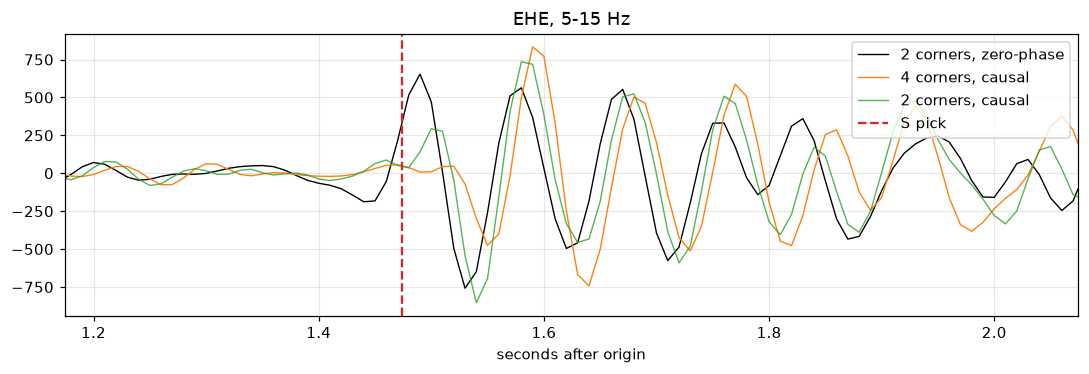

In [8]:
from scipy.signal import correlate, hilbert

def envelope(x):
    return np.abs(hilbert(x - x.mean()))

def envelope_lag(a, b, max_lag=0.1):
    """Time (s) by which the envelope of a lags the envelope of b."""
    ea, eb = envelope(a), envelope(b)
    cc = correlate(ea - ea.mean(), eb - eb.mean(), mode="full")
    lags = np.arange(-len(eb) + 1, len(ea)) / fs
    keep = np.abs(lags) <= max_lag
    return lags[keep][np.argmax(cc[keep])]

lo, hi = 5, 15
s0, s1 = s_off - 0.3, s_off + 0.6                  # window around S, seconds after trace start
def onset(f):
    """Seconds after the S pick at which the envelope first reaches half its maximum."""
    e = envelope(window(f, s0, s1))
    return np.argmax(e > 0.5 * e.max()) / fs + s0 - s_off

zero = tr.copy().filter("bandpass", freqmin=lo, freqmax=hi, corners=2, zerophase=True)
causal4 = tr.copy().filter("bandpass", freqmin=lo, freqmax=hi, corners=4, zerophase=False)
causal2 = tr.copy().filter("bandpass", freqmin=lo, freqmax=hi, corners=2, zerophase=False)
for name, f in [("2 corners, zero-phase", zero), ("4 corners, causal", causal4),
                ("2 corners, causal (the pipeline's filter bank)", causal2)]:
    print(f"{name:48s} envelope lag vs zero-phase {envelope_lag(window(f, s0, s1), window(zero, s0, s1)) * 1000:3.0f} ms,"
          f"  onset {onset(f) * 1000:+4.0f} ms from the S pick")

# the same causal filter on both horizontals: does the N-E relative timing change?
n_tr = ev.select(channel="??N")[0].copy().detrend("linear")
for name, kw in [("zero-phase", dict(corners=2, zerophase=True)), ("causal", dict(corners=4, zerophase=False))]:
    fn = n_tr.copy().filter("bandpass", freqmin=lo, freqmax=hi, **kw)
    fe = tr.copy().filter("bandpass", freqmin=lo, freqmax=hi, **kw)
    a, b = window(fn, s0, s1), window(fe, s0, s1)
    cc = correlate(a - a.mean(), b - b.mean(), mode="full"); lags = np.arange(-len(b) + 1, len(a)) / fs
    keep = np.abs(lags) <= 0.05
    print(f"N relative to E around S, {name:10s}: {lags[keep][np.argmax(cc[keep])] * 1000:3.0f} ms")

fig, ax = plt.subplots(figsize=(10, 3.5))
t = tr.times(reftime=origin)
ax.plot(t, zero.data, "k", lw=0.9, label="2 corners, zero-phase")
ax.plot(t, causal4.data, "tab:orange", lw=0.9, label="4 corners, causal")
ax.plot(t, causal2.data, "tab:green", lw=0.9, alpha=0.8, label="2 corners, causal")
ax.axvline(s_time - origin, color="tab:red", ls="--", label="S pick")
ax.set_xlim(s_time - origin - 0.3, s_time - origin + 0.6); ax.set_xlabel("seconds after origin"); ax.legend(loc="upper right")
ax.set_title(f"EHE, {lo}-{hi} Hz")
plt.tight_layout()

**The shift.** The 4-corner causal filter moves the S wave about 80 ms later (8 samples), and the 2-corner causal filter the pipeline uses about 40 ms. The zero-phase filter does not shift it, but look at the black trace just before the pick: a small swing appears *before* the S onset, although here the envelope only reaches half height at the pick itself. A zero-phase filter is acausal; running it backwards smears a little energy to earlier times. Neither choice is free: causal filters delay, zero-phase filters leak backwards.

**Does it matter for splitting?** Less than you might think for dt, more than you might think for everything else:

- dt is a delay *between* two horizontal components, and both get the same filter, so a pure delay cancels. The filter also distorts the waveform shape, though, and the N-E lag around S moves by one sample (10 ms) between the zero-phase and causal versions here.
- Everything placed *from the pick* sees the S wave about 40 ms later than the pick says: the SNR windows, the dominant-period window, and the swspy analysis windows. That is the same size as the 0.03 s pick shift that flips Q_w for this event in notebook 07, section 6.

So the honest answer to "why zero-phase?" is that the pipeline does not use it, and whether it should is a fair question to raise with Michael, together with a measurement of how much it changes the results.

### Exercise 2: the SNR depends on its windows

In [9]:
rows = []
for pre, post in [(0.4, 0.2), (0.2, 0.1), (1.0, 0.5)]:
    r = {"pre / post (s)": f"{pre} / {post}"}
    for lo, hi in bands:
        f = tr.copy().filter("bandpass", freqmin=lo, freqmax=hi, corners=2, zerophase=True)
        r[f"{lo}-{hi} Hz"] = simple_snr(f, s_off, pre=pre, post=post)
    r["raw"] = simple_snr(tr, s_off, pre=pre, post=post)
    rows.append(r)
snr_windows = pd.DataFrame(rows).set_index("pre / post (s)").round(2)
snr_windows

,1-5 Hz,5-15 Hz,10-30 Hz,raw
pre / post (s),,,,
0.4 / 0.2,5.97,8.08,5.92,7.92
0.2 / 0.1,3.04,6.62,5.59,7.62
1.0 / 0.5,7.19,6.88,5.04,6.85


The SNR depends on its windows, and how much depends on the band:

- **5-15 Hz moves the least** (6.6 to 8.1). Even the 0.1 s window after S holds one or two periods of a 10 Hz wave.
- **1-5 Hz moves by a factor of more than 2** (3.0 to 7.2). A 0.1 s window is shorter than one period of a 1 to 5 Hz wave (0.2 to 1 s), so it catches a fraction of a cycle; the 0.5 s window catches the bulk of the low-frequency S energy.
- **10-30 Hz and raw** move by about 15 percent.

Every version passes an "SNR at least 2" gate for this event, which has a clear S wave. One more catch in the 1.0 / 0.5 row: S-P here is only 0.59 s, so a 1.0 s window before S reaches back past the P pick, and the "noise" includes the P wave. The pipeline's version guards against this: it never starts the noise window earlier than halfway between P and S (`mid_samples` in `sws_functions._s_wave_snr_prefiltered`).

### Exercise 3: which band does the filter bank pick?

Five events, as asked, sampled from the cached ones with a fixed seed so the choice is repeatable. Then the same question for every STAR event at once, from the `filter_band` column of the results file. Careful with that column: the band is chosen on the horizontal SNR, and the results file predates STAR's orientation fix, so its "horizontals" were the vertical and east records. The commentary below gives the corrected counts as well.

In [10]:
cached = data.describe_cache("STAR").query("complete").evid
picked = []
for _, r in cat[cat.evid.isin(cached) & (cat.evid != row.evid)].sample(5, random_state=3).iterrows():
    e = data.get_event_stream("STAR", r, allow_download=False)
    _, pt, st_, _, _ = measure.pick_offsets(e, r)
    b, _, s, _, by_band = swsf.try_filters(e, pt, st_)
    ranked = pd.Series(by_band).dropna().sort_values(ascending=False)
    picked.append({"evid": r.evid, "M": r.event_magnitude, "chosen band": b, "SNR": round(s, 1),
                   "runner-up": ranked.index[1], "runner-up SNR": round(ranked.iloc[1], 1)})
print(pd.DataFrame(picked).to_string(index=False))

res = pd.read_csv(paths.station_results_csv("STAR"))
chosen = res.filter_band.dropna().value_counts()
print(f"\nall {chosen.sum()} STAR events with a chosen band:")
print((chosen / chosen.sum() * 100).round(1).rename("percent").to_string())

    evid    M chosen band  SNR   runner-up  runner-up SNR
62139482 0.65  (1.0, 5.0)  7.1 (5.0, 10.0)            6.9
62144602 1.87  (1.0, 5.0)  2.3  (1.0, 8.0)            1.8
62137262 0.42  (1.0, 5.0) 13.2  (2.0, 8.0)            9.3
62135552 0.57  (1.0, 5.0)  4.6  (1.0, 8.0)            3.5
62134552 0.17  (2.0, 8.0)  7.7  (1.0, 5.0)            7.1

all 900 STAR events with a chosen band:
filter_band
(1.0, 5.0)      42.6
(5.0, 10.0)      9.2
(3.0, 5.0)       7.2
(10.0, 45.0)     7.0
(1.0, 8.0)       6.4
(1.0, 15.0)      5.3
(5.0, 15.0)      4.9
(5.0, 45.0)      4.2
(2.0, 8.0)       4.0
(1.0, 20.0)      3.1
(10.0, 20.0)     2.6
(3.0, 15.0)      1.7
(5.0, 30.0)      1.2
(3.0, 30.0)      0.6


For these five events the bank chose 1-5 Hz four times and 2-8 Hz once: never 5-15 Hz. The runner-up is often close (7.1 against 6.9, 7.7 against 7.1), and for 62139482 it is a very different band (5-10 Hz just behind 1-5 Hz), so the "best band" is often a near tie decided by a noisy SNR. Note 62144602: magnitude 1.9, the largest of the five, but its best SNR is 2.3, barely above the pipeline's gate of 2 (a larger event does not guarantee a cleaner S wave at one station).

Across all 900 STAR events in the results file (pre-fix), 1-5 Hz wins 43 percent of the time, and 5-10 or 5-15 Hz together only 14 percent. Re-measured with the components corrected, 1-5 Hz wins 58 percent, 5-10 Hz 15 percent and 5-15 Hz under 1 percent. So on the true horizontals one band wins a majority, but a fixed band would still give up the best band for 42 percent of events. 1-5 Hz is the closest to a sensible default, but it is also the coarsest: its waves have periods of 0.2 s or more, while the delays we are after are 0.02 to 0.04 s. That trade-off between SNR and resolution is why the pipeline lets the data choose, and why `filter_band` belongs in the benchmark of notebook 07.

### Exercise 4 (stretch): a spectrogram of the whole trace

A spectrogram is a series of short spectra, one per time window. Windows of 0.32 s (32 samples) overlapping by 90 percent trade frequency resolution (about 3 Hz) for time resolution; with longer windows P and S, 0.6 s apart, would blur together.

Text(0.5, 1.0, 'EHE, evid 61504668: P (cyan) and S (dashed)')

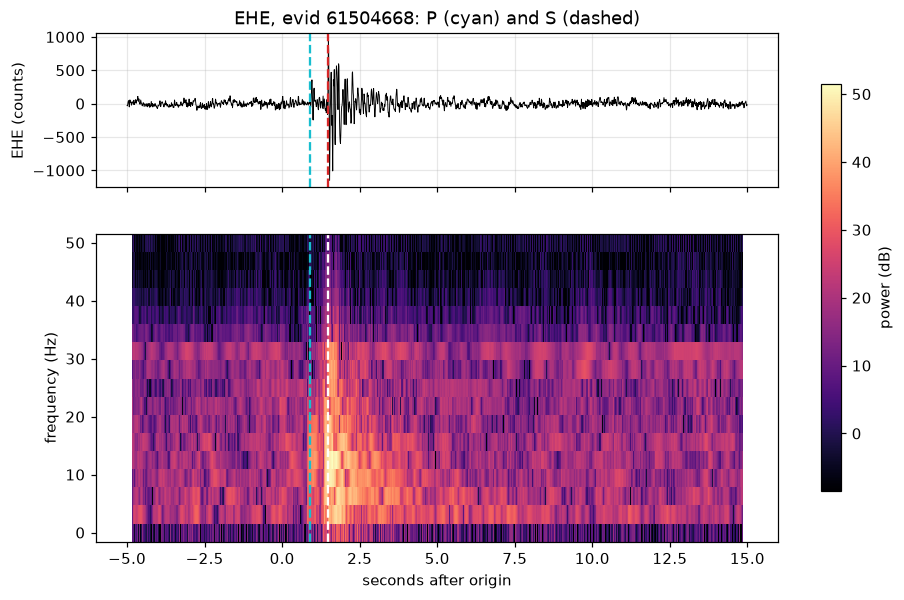

In [11]:
from scipy.signal import spectrogram

fig, axes = plt.subplots(2, 1, figsize=(10, 6), sharex=True, gridspec_kw={"height_ratios": [1, 2]})
t_tr = tr.times(reftime=origin)
axes[0].plot(t_tr, tr.data, "k", lw=0.6); axes[0].set_ylabel("EHE (counts)")
f_sg, t_sg, S = spectrogram(tr.data.astype(float), fs=fs, nperseg=32, noverlap=29, scaling="spectrum")
t_sg = t_sg + (tr.stats.starttime - origin)          # seconds after origin
pc = axes[1].pcolormesh(t_sg, f_sg, 10 * np.log10(S + 1e-12), shading="auto", cmap="magma",
                        vmin=np.percentile(10 * np.log10(S + 1e-12), 5))
fig.colorbar(pc, ax=axes, label="power (dB)", shrink=0.8, location="right")
for ax in axes:
    ax.axvline(p_time - origin, color="tab:cyan", ls="--"); ax.axvline(s_time - origin, color="w" if ax is axes[1] else "tab:red", ls="--")
axes[1].set_ylabel("frequency (Hz)"); axes[1].set_xlabel("seconds after origin"); axes[1].grid(False)
axes[0].set_title("EHE, evid 61504668: P (cyan) and S (dashed)")

- **Before P** (the first 5 s): a steady band of noise up to about 33 Hz and almost nothing above 35 Hz. This is the floor any signal has to beat.
- **P** (cyan): a clear but modest brightening between about 5 and 30 Hz, weaker than S. E is a horizontal channel, but not a quiet one for P: this event's ray reaches STAR about 30 degrees from vertical, from the east, so part of the P motion is on E, the radial direction.
- **S** (dashed): the brightest part of the picture, a burst from about 1.5 to 2.5 s that is broadband, reaching 30 Hz and strongest between about 3 and 15 Hz.
- **Coda**: after about 2.5 s the energy fades back into the noise band over the next few seconds, and the high frequencies go first, leaving 2 to 10 Hz. Scattered waves at high frequency are attenuated faster.

This is the time-frequency version of section 1: the spectrum told you *which* frequencies the S wave has, the spectrogram also tells you *when*, and why the filter bank and the windows have to be chosen together.